# Imports 

In [1]:
import pandas as pd
import numpy as np
# from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix
import joblib
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier
from sklearn.preprocessing import LabelEncoder

from elm import ELMClassifier

random_state=42

-----

# Functions

In [2]:
def train_validation_test_split(
        X, y, validation_size=0.1,
        test_size=0.1, random_state=42):
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    X_train, X_valid, y_train, y_valid = train_test_split(
        X_train, y_train,
        test_size=validation_size / (1 - test_size),
        random_state=random_state,
        stratify=y_train,
    )
    return X_train, X_valid, X_test, y_train, y_valid, y_test

In [3]:
import sklearn
sklearn.__version__

'0.20.4'

In [22]:
from scipy import stats

def confidence_interval(data, confidence=0.95):
    a = 1.0 * np.array(data)
    n = len(a)
    m, se = np.mean(a), stats.sem(a)
    h = se * stats.t.ppf((1 + confidence) / 2., n-1)
    return "{:.5f} ± {:.5f}".format(m, h)

In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize

def multiclass_roc_auc_score(y_true, y_pred, average="macro"):
    """
    Calculate the ROC AUC score for multiclass classification.
    
    Parameters:
        y_true (list or array): True class labels
        y_pred (list or array): Predictions, either probabilities or class labels
        average (str): 'macro' (default) averages the AUC of each class.
                       'weighted' accounts for class imbalance.
    
    Returns:
        float: ROC AUC score
    """
    # Determine the number of classes by the unique elements in the true class labels
    # y_true = np.array(y_true)
    # y_pred = np.array(y_pred)

    
    classes = np.unique(y_true)
    
    # Binarize the output labels for multiclass
    y_true_bin = label_binarize(y_true, classes=classes)
    
    # Check if y_pred is already in a one-hot encoded format
    if y_pred.shape[1] != len(classes):
        y_pred = label_binarize(y_pred, classes=classes)
    
    # Compute ROC AUC for each class and average
    auc_scores = [
        roc_auc_score(y_true_bin[:, i], y_pred[:, i])
        for i in range(len(classes))
    ]
    
    if average == "macro":
        return np.mean(auc_scores)
    elif average == "weighted":
        class_counts = np.bincount(y_true)
        weights = class_counts / float(len(y_true))
        return np.average(auc_scores, weights=weights[:len(classes)])
    else:
        raise ValueError("Unknown average type. Choose 'macro' or 'weighted'")


In [49]:
def report_model_performance(model, X_train, X_valid, X_test, y_train, y_valid, y_test):
    
    accuracy_best_param_cv = np.array([model.steps[-1][-1].cv_results_["split"+str(i)+"_test_Accuracy"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    precision_best_param_cv = np.array([model.steps[-1][-1].cv_results_["split"+str(i)+"_test_Precision"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    recall_best_param_cv = np.array([model.steps[-1][-1].cv_results_["split"+str(i)+"_test_Recall"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    f1_best_param_cv = np.array([model.steps[-1][-1].cv_results_["split"+str(i)+"_test_F1"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    roc_auc_best_param_cv = np.array([model.steps[-1][-1].cv_results_["split"+str(i)+"_test_ROC-AUC"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    
    
    best_param = model.steps[-1][-1].best_params_
    print "Best parameters:" + str(best_param)
    print "Cross Validation accuracy Array:" + str(accuracy_best_param_cv)
    print "Validation accuracy:" + confidence_interval(accuracy_best_param_cv)
    
    print "Cross Validation precision Array:" + str(precision_best_param_cv)
    print "Validation precision:" + confidence_interval(precision_best_param_cv)
    
    print "Cross Validation recall Array:" + str(recall_best_param_cv)
    print "Validation recall:" + confidence_interval(recall_best_param_cv)
    
    print "Cross Validation f1 Array:" + str(f1_best_param_cv)
    print "Validation f1:" + confidence_interval(f1_best_param_cv)
    
    print "Cross Validation roc_auc Array:" + str(roc_auc_best_param_cv)
    print "Validation roc_auc:" + confidence_interval(roc_auc_best_param_cv)
    
    print() 
    print()
    y_train_pred = model.predict(X_train)
    y_train_pred_proba = model.predict_proba(X_train)
    y_valid_pred = model.predict(X_valid)
    y_valid_pred_proba = model.predict_proba(X_valid)
    y_test_pred = model.predict(X_test)
    y_test_pred_proba = model.predict_proba(X_test)
    print("===> Training performance")
    print(classification_report(y_train, y_train_pred, digits=5))
    print("Training ROC-AUC:" + str(multiclass_roc_auc_score(y_train, y_train_pred_proba)).format(5))
    
    print("===> Validation performance")
    print(classification_report(y_valid, y_valid_pred, digits=5))
    print("Validation ROC-AUC:" + str(multiclass_roc_auc_score(y_valid, y_valid_pred_proba)).format(5))
    print("===> Test performance")
    print(classification_report(y_test, y_test_pred, digits=5))
    print("Testing ROC-AUC:" + str(multiclass_roc_auc_score(y_test, y_test_pred_proba)).format(5))
    
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_train, y_train_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Train Confusion Matrix")
        plt.show()

    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_valid, y_valid_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Validation Confusion Matrix")
        plt.show()
        
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_test, y_test_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Test Confusion Matrix")
        plt.show()

In [5]:
def save_model(model, model_name):
    joblib.dump(model, str(model_name) + ".joblib")

# Read Dataset

In [6]:
X = pd.read_csv("iris.data", header=None)

In [7]:
y = X[4]
X = X.drop(columns=[4])

# Descritive statistics

In [8]:
X.describe()

,0,1,2,3
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [9]:
y.value_counts(normalize=True)

Iris-setosa        0.333333
Iris-versicolor    0.333333
Iris-virginica     0.333333
Name: 4, dtype: float64

In [10]:
y = LabelEncoder().fit_transform(y)

## Split Dataset

In [11]:
X_train, X_valid, X_test, y_train, y_valid, y_test = train_validation_test_split(
    X, y, validation_size=0.1, test_size=0.1, random_state=random_state
)

In [12]:
X_train.shape, X_valid.shape, X_test.shape

((119, 4), (16, 4), (15, 4))

# Pre-processing

## Scaling the data

In [13]:
scaler_elm = MinMaxScaler()

# Model

## ELM

In [15]:
from random_layer import RandomLayer

In [38]:
from sklearn.metrics import make_scorer

cv = StratifiedShuffleSplit(n_splits=100, test_size=0.2, random_state=random_state)
elm = ELMClassifier()
roc_auc_scorer = make_scorer(multiclass_roc_auc_score, needs_proba=True)

scoring = {
    "Accuracy": "accuracy", "ROC-AUC": roc_auc_scorer,
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}


elm_opt = RandomizedSearchCV(
    elm,
    {
        "n_hidden": (10, 100),
        "activation_func": ['multiquadric', 'hardlim', 'tribas', 'tanh', 'sigmoid', 'sine', 'softlim', 'gaussian', 'inv_multiquadric', 'inv_tribas'],
        "alpha": (0.5, 1),
    },
    n_iter=50,
    cv=cv,
    n_jobs=-1,
    verbose=2,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_elm = Pipeline([("scaler", scaler_elm), ("elm", elm_opt)])

In [39]:
pipe_elm.fit(X_train, y_train)

Fitting 100 folds for each of 40 candidates, totalling 4000 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.


[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:    0.8s
[Parallel(n_jobs=-1)]: Done 137 tasks      | elapsed:    4.4s
[Parallel(n_jobs=-1)]: Done 543 tasks      | elapsed:    9.5s
[Parallel(n_jobs=-1)]: Done 1050 tasks      | elapsed:   16.5s
[Parallel(n_jobs=-1)]: Done 1716 tasks      | elapsed:   26.1s
[Parallel(n_jobs=-1)]: Done 2333 tasks      | elapsed:   36.4s
[Parallel(n_jobs=-1)]: Done 3197 tasks      | elapsed:   50.8s
[Parallel(n_jobs=-1)]: Done 3961 out of 4000 | elapsed:  1.0min remaining:    0.6s
[Parallel(n_jobs=-1)]: Done 4000 out of 4000 | elapsed:  1.0min finished


Pipeline(memory=None,
     steps=[('scaler', MinMaxScaler(copy=True, feature_range=(0, 1))), ('elm', RandomizedSearchCV(cv=StratifiedShuffleSplit(n_splits=100, random_state=42, test_size=0.2,
            train_size=None),
          error_score='raise-deprecating',
          estimator=ELMClassifier(activation_args=None, activa...', 'Precision': 'precision_macro', 'F1': 'f1_macro', 'Accuracy': 'accuracy'},
          verbose=2))])

In [40]:
pipe_elm.score(X_test, y_test)

0.8666666666666667

In [44]:
pipe_elm.steps[-1][-1].cv_results_

/home/matheusalb/anaconda3/envs/p27/lib/python2.7/site-packages/sklearn/utils/deprecation.py:125: FutureWarning: You are accessing a training score ('split70_train_Accuracy'), which will not be available by default any more in 0.21. If you need training scores, please set return_train_score=True
  warnings.warn(*warn_args, **warn_kwargs)
/home/matheusalb/anaconda3/envs/p27/lib/python2.7/site-packages/sklearn/utils/deprecation.py:125: FutureWarning: You are accessing a training score ('split67_train_Recall'), which will not be available by default any more in 0.21. If you need training scores, please set return_train_score=True
  warnings.warn(*warn_args, **warn_kwargs)
/home/matheusalb/anaconda3/envs/p27/lib/python2.7/site-packages/sklearn/utils/deprecation.py:125: FutureWarning: You are accessing a training score ('split51_train_Recall'), which will not be available by default any more in 0.21. If you need training scores, please set return_train_score=True
  warnings.warn(*warn_args,

{'split95_test_F1': array([1.        , 0.70718954, 0.91666667, 0.83703704, 0.16666667,
        0.16666667, 0.63929147, 0.91666667, 0.91534392, 0.95816993,
        0.8745098 , 0.71626984, 0.95816993, 0.82222222, 0.95816993,
        0.83703704, 0.95816993, 0.75      , 0.91534392, 0.67385621,
        0.95816993, 0.78407557, 0.95816993, 0.79259259, 0.91534392,
        0.95816993, 0.91534392, 0.79482038, 0.8745098 , 0.53333333,
        0.91666667, 0.79640523, 0.95816993, 0.83333333, 0.95816993,
        0.75793651, 0.91666667, 0.95816993, 0.87044534, 0.75630252]),
 'split93_test_Precision': array([1.        , 1.        , 0.96296296, 0.79365079, 0.27368421,
        0.82222222, 0.88888889, 0.96296296, 0.39160839, 0.96296296,
        0.96296296, 0.93333333, 1.        , 0.75555556, 0.96296296,
        0.75324675, 1.        , 0.77777778, 0.93333333, 0.74074074,
        0.96296296, 0.90909091, 0.93333333, 0.79047619, 1.        ,
        1.        , 1.        , 0.93333333, 1.        , 0.67222222,
 

Best parameters:{'alpha': 0.5, 'activation_func': 'tanh', 'n_hidden': 10}
Cross Validation accuracy Array:[1.         1.         0.95833333 1.         1.         0.95833333
 1.         1.         0.95833333 1.         0.95833333 1.
 1.         0.875      1.         0.95833333 0.95833333 0.95833333
 0.95833333 1.         0.95833333 1.         0.95833333 0.95833333
 1.         1.         1.         0.95833333 0.95833333 1.
 0.91666667 0.95833333 1.         0.95833333 1.         1.
 1.         1.         0.95833333 0.91666667 1.         0.95833333
 0.95833333 1.         0.95833333 0.95833333 1.         0.95833333
 0.95833333 0.91666667 1.         0.95833333 0.91666667 0.875
 1.         1.         0.95833333 0.91666667 1.         0.95833333
 0.95833333 0.95833333 0.95833333 0.95833333 0.95833333 0.95833333
 1.         0.875      1.         1.         0.95833333 1.
 0.91666667 1.         0.95833333 0.91666667 1.         1.
 0.95833333 0.95833333 1.         0.95833333 0.91666667 1.
 1.      

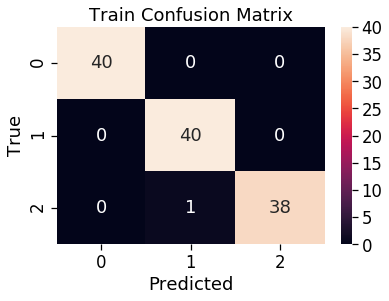

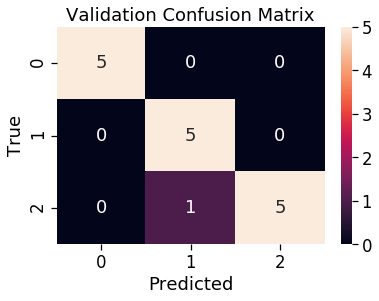

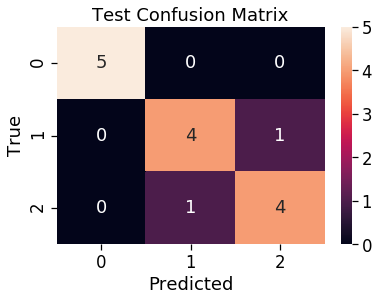

In [50]:
report_model_performance(pipe_elm, X_train, X_valid, X_test, y_train, y_valid, y_test)